# Notebook 16 — Controlled Ablations at the Selected Configuration

**Hyperparameter-optimisation experiment · Soccer Event Transformer · Track A model family**

| Item | Content |
|---|---|
| **Question** | For the selected model, how does predictive performance change when the model is trained without player and team identity (B7), without any identity (B5), or without context (B6)? In particular, what is the identity value (B7 − B8)? |
| **Full model (B8)** | The selected model: 4 layers, 2 heads, d_model 128, d_ff 512, K = 16, T300 encoding, learning rate 3e-4, weight decay 0.01, seeds 100–104. **Not retrained and not re-evaluated on test**: its validation predictions come from its run folders, its test predictions from the files saved at its single test evaluation. |
| **Restricted models** | B5 context-only, B6 identity-only, B7 role-only: the same architecture and training setting, trained from scratch here with some factor groups switched off, seeds 100–102. |
| **What kind of ablation this is** | Each comparison is between two separately trained models that receive different information. It measures how much predictive information a factor group adds under this training setup. It is **not** an intervention on the trained weights of the selected model, and it says nothing about how the selected model uses identity internally. |
| **What is decided here** | Nothing. No number in this notebook is used to choose anything. |
| **Test data** | B5–B7 are evaluated on test only if `EVALUATE_ABLATIONS_ON_TEST = True` is set in Section 2 before the run (it is set to `True`). |
| **Outputs** | `experiments/hyperparameter_optimisation/ablations/` |



## 0. Provenance

| Component | Source | Status here |
|---|---|---|
| Data, encoding, splits, windows, evaluation views | `artifacts/` | read only |
| Model code, training loop, metrics, bootstrap | `src/` | imported, never rewritten |
| Restricted-model definitions (factor groups) | the Track A restricted-model protocol | copied verbatim (Section 2) |
| Seeds of the restricted models (100–102) | the Track A restricted-model protocol | unchanged |
| Selected configuration and training setting | `experiments/hyperparameter_optimisation/config/frozen_config.json` | read only |
| B8 = selected model | its five final runs (`13_final_runs.csv`) and saved test predictions | read only |
| Reference-configuration ablation predictions (REF-2L, REF-4L) | Track A test predictions; 4-layer depth-check test predictions | read only; used only as context in Sections 8–10 |

**Reference configurations.** REF-2L is the frozen Track A model (2 layers, weight decay 0.1) and REF-4L the 4-layer model of an earlier depth check (weight decay 0.1). Their own restricted models were trained when those configurations were evaluated. They are not part of this ablation; their saved test predictions are shown next to the selected model's results so that the signs and sizes can be compared.

## 1. Environment

Every earlier result file (Track A, the 4-layer depth check, the optimisation experiment) is fingerprinted before any step, and checked again at the end (Section 11).

**RESULT.** 111 existing result files fingerprinted.

In [ ]:
# ---------------------------------------------------------------------------
# Environment setup (same layout as notebooks 08-14 of this experiment)
# ---------------------------------------------------------------------------
import os
import sys
import json
import time
import shutil
import hashlib
import importlib
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

PROJECT_DIR = Path(os.environ.get("TRACK_A_DIR", "/content/drive/MyDrive/soccer_mi/track_a"))
RUN_MODE = os.environ.get("TRACK_A_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

EXISTING_DIR = PROJECT_DIR if RUN_MODE == "full" else PROJECT_DIR / "smoke"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
EXISTING_RUNS_DIR = EXISTING_DIR / "runs"
EXISTING_RESULTS_DIR = EXISTING_DIR / "results"
EXISTING_FROZEN_CONFIG = EXISTING_DIR / "config" / "frozen_config.json"
BENCH_DIR = EXISTING_DIR / "benchmarks" / "track_a_4layer"
OPT_DIR = EXISTING_DIR / "experiments" / "hyperparameter_optimisation"
OPT_RESULTS_DIR = OPT_DIR / "results"
OPT_CONFIG_PATH = OPT_DIR / "config" / "frozen_config.json"

WORK_DIR = OPT_DIR / "ablations"
RUNS_DIR = WORK_DIR / "runs"
RESULTS_DIR = WORK_DIR / "results"
FIGURES_DIR = WORK_DIR / "figures"
CONFIG_DIR = WORK_DIR / "config"
MANIFEST_DIR = WORK_DIR / "manifests"
LOG_DIR = WORK_DIR / "logs"
for folder in [RUNS_DIR, RESULTS_DIR, FIGURES_DIR, CONFIG_DIR, MANIFEST_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = MANIFEST_DIR / "experiment_manifest.jsonl"


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def load_json(path):
    with open(path) as handle:
        return json.load(handle)


print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("Outputs of this notebook:", WORK_DIR)

Mounted at /content/drive
Colab: True | RUN_MODE: full
Outputs of this notebook: /content/drive/MyDrive/soccer_mi/track_a/experiments/hyperparameter_optimisation/ablations


In [ ]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt


import src.data as data
import src.batching as batching
import src.metrics as metrics
import src.model as model_module
import src.training as training
import src.analysis as analysis
import src.evaluation as evaluation
for module in [data, batching, metrics, model_module, training, analysis, evaluation]:
    importlib.reload(module)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 120)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "full" and DEVICE != "cuda":
    raise RuntimeError("BLOCKED: full-mode training requires a GPU. In Colab: Runtime > Change runtime type > GPU.")
N_BOOT = 2000 if RUN_MODE == "full" else 50

events = pd.read_parquet(ARTIFACTS_DIR / "events_prepared.parquet")
targets = events["action_id"].to_numpy().astype("int64")
match_ids = events["match_id"].to_numpy()

TRACK_A_FROZEN = load_json(EXISTING_FROZEN_CONFIG)
TRACK_A_HYPERPARAMETERS = load_json(EXISTING_RESULTS_DIR / "04_selected_hyperparameters.json")
SELECTED = load_json(OPT_CONFIG_PATH)

ENCODING = TRACK_A_FROZEN["encoding"]
POSSESSION_FEATURES = TRACK_A_FROZEN["possession_features"]
STRIDE = TRACK_A_FROZEN["stride"]
FINAL_CONTEXT = SELECTED["context_length"]
FINAL_SEEDS = SELECTED["seed_policy"]["final_seeds"]

print("Events:", len(events), "| device:", DEVICE)
print("Selected configuration (notebook 12):",
      json.dumps({key: SELECTED[key] for key in ["context_length", "model", "training"]}))
print("Final seeds:", FINAL_SEEDS)

Events: 658905 | device: cuda
Selected configuration (notebook 12): {"context_length": 16, "model": {"n_layers": 4, "n_heads": 2, "d_model": 128, "d_ff": 512}, "training": {"learning_rate": 0.0003, "weight_decay": 0.01, "max_epochs": 30, "batch_size": 256, "warmup_fraction": 0.05, "min_lr_ratio": 0.1, "grad_clip": 1.0, "patience": 5}}
Final seeds: [100, 101, 102, 103, 104]


In [ ]:
def fingerprint_folder(folder, patterns=("*.json", "*.csv", "*.npz", "*.jsonl")):
    fingerprints = {}
    for pattern in patterns:
        for path in sorted(Path(folder).rglob(pattern)):
            if WORK_DIR in path.parents:
                continue
            fingerprints[str(path.relative_to(EXISTING_DIR))] = file_sha256(path)
    return fingerprints


SNAPSHOT_FOLDERS = [EXISTING_RESULTS_DIR, BENCH_DIR / "results", OPT_RESULTS_DIR, OPT_DIR / "config",
                    OPT_DIR / "logs", EXISTING_DIR / "config"]
snapshot_before = {}
for folder in SNAPSHOT_FOLDERS:
    if folder.exists():
        snapshot_before.update(fingerprint_folder(folder))
training.save_json(MANIFEST_DIR / "snapshot_before.json", snapshot_before)
print(f"{len(snapshot_before)} existing result files fingerprinted.")

111 existing result files fingerprinted.


## 2. Test-split policy (set before running) and the frozen plan

The selected model has already been evaluated on test once and is not evaluated again.

B5–B7 trained here are new models. The Track A restricted-model protocol evaluated its restricted models on test, so replicating it exactly means evaluating these on test too. That is a new, logged access to the test split, for new frozen models, with no decision depending on it. The alternative is to report B5–B7 on validation only.

The flag is set to `True` or `False` **before** running. It is written into the plan file, which is written before any training and cannot be changed afterwards (a re-run with a different plan stops).

**Plan contents.** Factor groups of B5, B6 and B7 (below); seeds 100–102 for the restricted models and 100–104 for B8; the selected architecture and training setting with the SHA-256 of the configuration file; `full_model_retrained: false`, `full_model_test_reevaluated: false`; the decision rule.

| Model | Factor groups received |
|---|---|
| B5 context-only | competition, space, time, state, history |
| B6 identity-only | player, team, role |
| B7 role-only | role, competition, space, time, state, history |
| B8 full (selected model) | all groups |

Positional embeddings are part of every model.

In [ ]:
EVALUATE_ABLATIONS_ON_TEST = True

if EVALUATE_ABLATIONS_ON_TEST not in (True, False):
    raise RuntimeError("BLOCKED: set EVALUATE_ABLATIONS_ON_TEST to True or False before running this notebook.")
print("Restricted models evaluated on test:", EVALUATE_ABLATIONS_ON_TEST)

Restricted models evaluated on test: True


In [ ]:

GROUPS_B5 = ["competition", "space", "time", "state", "history"]                 # context-only
GROUPS_B6 = ["player", "team", "role"]                                           # identity-only
GROUPS_B7 = ["role", "competition", "space", "time", "state", "history"]         # role-only
RESTRICTED_GROUPS = {"B5 context-only": GROUPS_B5, "B6 identity-only": GROUPS_B6, "B7 role-only": GROUPS_B7}
BASELINE_SEEDS = [100, 101, 102]

plan_path = CONFIG_DIR / "frozen_config.json"
plan = {
    "purpose": "Restricted models B5-B7 at the configuration selected in notebook 12 (Track A notebook 06 protocol)",
    "selected_config_file": str(OPT_CONFIG_PATH),
    "selected_config_sha256": file_sha256(OPT_CONFIG_PATH),
    "context_length": FINAL_CONTEXT, "model": SELECTED["model"], "training": SELECTED["training"],
    "encoding": ENCODING, "possession_features": POSSESSION_FEATURES, "stride": STRIDE,
    "restricted_groups": RESTRICTED_GROUPS, "restricted_seeds": BASELINE_SEEDS, "full_model_seeds": FINAL_SEEDS,
    "full_model_retrained": False, "full_model_test_reevaluated": False,
    "evaluate_restricted_models_on_test": EVALUATE_ABLATIONS_ON_TEST,
    "decision_rule": "Track A notebook 04 Section 2.5 (bootstrap CI below zero and complete seed separation)",
    "run_mode": RUN_MODE,
    "written_at": pd.Timestamp.now(tz="UTC").isoformat(),
}
if plan_path.exists():
    previous = load_json(plan_path)
    changed = {key for key in plan if key != "written_at" and previous.get(key) != plan[key]}
    if changed:
        raise RuntimeError(f"BLOCKED: the frozen plan already exists and differs in {sorted(changed)}. "
                           "A plan is not changed after it is written.")
    print("Frozen plan already written on", previous["written_at"], "- unchanged.")
else:
    training.save_json(plan_path, plan)
    print("Frozen plan written before any training:", plan_path)

Frozen plan written before any training: /content/drive/MyDrive/soccer_mi/track_a/experiments/hyperparameter_optimisation/ablations/config/frozen_config.json


## 3. The selected model's own files

The five runs of the selected model are located through `13_final_runs.csv` and each stored configuration is checked against the frozen configuration. No run is retrained.

**RESULT.** All five runs match. Primary checkpoint: seed 103. Validation NLL by seed: 0.9067, 0.9018, 0.9056, 0.9044, 0.8982; best epochs 7–10.

In [ ]:
final_table = pd.read_csv(OPT_RESULTS_DIR / "13_final_runs.csv")
final_validation = load_json(OPT_RESULTS_DIR / "13_final_validation.json")
sel_runs = [Path(path) for path in final_table.sort_values("seed")["run_dir"]]
PRIMARY_RUN_NAME = final_validation["primary_run"]
PRIMARY_SEED = final_validation["primary_seed"]

mismatches = []
for run_dir in sel_runs:
    run_config = load_json(run_dir / "run_config.json")
    for key in ["n_layers", "n_heads", "d_model", "d_ff"]:
        if run_config["model"][key] != SELECTED["model"][key]:
            mismatches.append((run_dir.name, key))
    if run_config["context_length"] != FINAL_CONTEXT:
        mismatches.append((run_dir.name, "context_length"))
    for key in ["learning_rate", "weight_decay"]:
        if abs(run_config["training"][key] - SELECTED["training"][key]) > 1e-12:
            mismatches.append((run_dir.name, key))
    if run_config.get("encoding") != ENCODING:
        mismatches.append((run_dir.name, "encoding"))
if mismatches:
    raise RuntimeError(f"BLOCKED: notebook 13 runs do not match the notebook 12 configuration: {mismatches}")
print(f"{len(sel_runs)} runs of the selected model found; all match the notebook 12 configuration.")
print(f"Primary checkpoint: seed {PRIMARY_SEED} ({PRIMARY_RUN_NAME})")
sel_summary = analysis.seed_summary(sel_runs)
sel_summary.round(4)

5 runs of the selected model found; all match the notebook 12 configuration.
Primary checkpoint: seed 103 (transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.01_s103)


,run,seed,best epoch,epochs run,diverged,val NLL,val accuracy,val macro-F1,train NLL,minutes
0,transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.01_s100,100,7,12,False,0.9067,0.6207,0.5456,0.8495,1.6084
1,transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.01_s101,101,7,12,False,0.9018,0.6224,0.5656,0.8467,1.5911
2,transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.01_s102,102,9,14,False,0.9056,0.6180,0.5601,0.8225,1.9635
3,transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.01_s103,103,7,12,False,0.9044,0.6209,0.5575,0.8480,1.6829
4,transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.01_s104,104,10,15,False,0.8982,0.6259,0.5630,0.8088,2.0174


## 4. Restricted models at the selected configuration

| Model | Receives | Question |
|---|---|---|
| **B5 context-only** | competition, space, time, game state, history, position — no player, team or role | How well can actions be predicted without identity? |
| **B6 identity-only** | player, team, role, position — no context | How well from identity alone? |
| **B7 role-only** | everything except player and team | How much do player and team add beyond role? **B7 vs B8 is the identity-value comparison.** |

**Control.** Architecture (4 layers, 2 heads, d_model 128, d_ff 512, K = 16) and training setting (learning rate 3e-4, weight decay 0.01, up to 30 epochs, early stopping) are exactly those of the selected model. Only the information received differs. The notebook stops if the selected setting changes batch size or warm-up, since the restricted configurations would then need extending.

**RESULT.** Validation NLL by seed (100, 101, 102): B5 0.8976, 0.8967, 0.8977; B6 1.5922, 1.5451, 1.5922; B7 0.8869, 0.8836, 0.8870. No run diverged. Parameter counts: B5 835,471, B6 872,975, B7 838,799.

In [ ]:
def restricted_config(seed, use_groups):
    """Run configuration in the notebook 13 format, with the factor groups of Track A notebook 06."""
    model = {"n_layers": SELECTED["model"]["n_layers"], "n_heads": SELECTED["model"]["n_heads"],
             "d_model": SELECTED["model"]["d_model"], "d_ff": SELECTED["model"]["d_ff"],
             "use_groups": list(use_groups)}
    return {"model_type": "transformer", "encoding": ENCODING, "possession_features": POSSESSION_FEATURES,
            "context_length": FINAL_CONTEXT, "stride": STRIDE, "seed": seed, "model": model,
            "training": {"learning_rate": SELECTED["training"]["learning_rate"],
                         "weight_decay": SELECTED["training"]["weight_decay"],
                         "max_epochs": SELECTED["training"]["max_epochs"]}}


for key in ["batch_size", "warmup_fraction"]:
    if SELECTED["training"][key] != training.DEFAULT_TRAINING[key]:
        raise RuntimeError(f"BLOCKED: the selected training setting changes {key}; extend restricted_config before training.")

final_bundle = training.prepare_data(events, ARTIFACTS_DIR, ENCODING, POSSESSION_FEATURES, FINAL_CONTEXT, STRIDE,
                                     DEVICE, RUN_MODE)
restricted_runs = {name: [] for name in RESTRICTED_GROUPS}
restricted_rows = []
for name, groups in RESTRICTED_GROUPS.items():
    for seed in BASELINE_SEEDS:
        config = restricted_config(seed, groups)
        result = training.train_run(config, final_bundle, RUNS_DIR, MANIFEST_PATH, keep_every_epoch=False, verbose=True)
        run_dir = RUNS_DIR / result["run_name"]
        restricted_runs[name].append(run_dir)
        restricted_rows.append({"model": name, "seed": seed, "parameters": result["parameter_counts"]["total"],
                                "val_nll": result["val_metrics"]["nll"], "val_accuracy": result["val_metrics"]["accuracy"],
                                "val_macro_f1": result["val_metrics"]["macro_f1"], "best_epoch": result["best_epoch"],
                                "epochs_run": result["epochs_run"], "diverged": result["diverged"],
                                "run_dir": str(run_dir)})
restricted_table = pd.DataFrame(restricted_rows)
restricted_table.to_csv(RESULTS_DIR / "16_restricted_runs.csv", index=False)
restricted_table.drop(columns=["run_dir"]).round(4)

[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-competition+space+time+state+history_lr0.0003_wd0.01_s100] epoch  1 | train loss 1.5999 | val NLL 1.0922 | val acc 0.5859 | val macro-F1 0.5030 | 8s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-competition+space+time+state+history_lr0.0003_wd0.01_s100] epoch  2 | train loss 1.0269 | val NLL 0.9963 | val acc 0.5888 | val macro-F1 0.4977 | 9s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-competition+space+time+state+history_lr0.0003_wd0.01_s100] epoch  3 | train loss 0.9603 | val NLL 0.9477 | val acc 0.6078 | val macro-F1 0.5389 | 7s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-competition+space+time+state+history_lr0.0003_wd0.01_s100] epoch  4 | train loss 0.9350 | val NLL 0.9319 | val acc 0.6076 | val macro-F1 0.5442 | 8s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-competition+space+time+state+history_lr0.0003_wd0.01_s100] epoch  5 | train loss 0.9210 | val NLL 0.9219 | val acc 0.6131 | val macro-F1 0.5328 | 8s


,model,seed,parameters,val_nll,val_accuracy,val_macro_f1,best_epoch,epochs_run,diverged
0,B5 context-only,100,835471,0.8976,0.6232,0.5590,12,17,False
1,B5 context-only,101,835471,0.8967,0.6239,0.5626,11,16,False
2,B5 context-only,102,835471,0.8977,0.6238,0.5576,13,18,False
3,B6 identity-only,100,872975,1.5922,0.4028,0.2048,3,8,False
4,B6 identity-only,101,872975,1.5451,0.4089,0.2204,4,9,False
5,B6 identity-only,102,872975,1.5922,0.4060,0.2223,5,10,False
6,B7 role-only,100,838799,0.8869,0.6281,0.5735,13,18,False
7,B7 role-only,101,838799,0.8836,0.6304,0.5651,10,15,False
8,B7 role-only,102,838799,0.8870,0.6259,0.5759,10,15,False


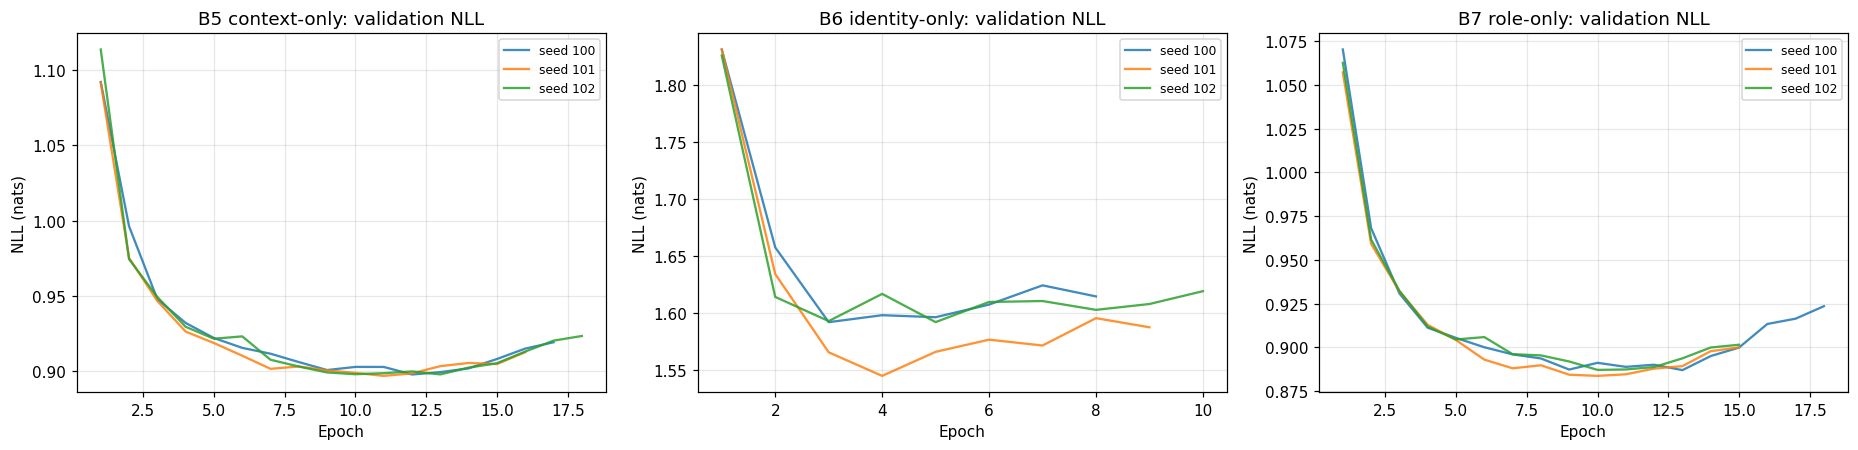

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for axis, (name, run_dirs) in zip(axes, restricted_runs.items()):
    for run_dir in run_dirs:
        history = analysis.load_history(run_dir)
        seed = load_json(run_dir / "run_config.json")["seed"]
        axis.plot(history["epoch"], history["val_nll"], alpha=0.85, label=f"seed {seed}")
    axis.set_title(f"{name}: validation NLL")
    axis.set_xlabel("Epoch")
    axis.set_ylabel("NLL (nats)")
    axis.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "16_restricted_training_curves.png", bbox_inches="tight")
plt.show()

**What are we looking at?** Validation NLL per epoch for each restricted model and seed. The checkpoint kept is the epoch with the lowest validation NLL, as for every other run.

**OBSERVATION.** B5 and B7 reach their best validation NLL later (epochs 10–13, 15–18 epochs run) than B8 did (best epochs 7–10). B6 reaches its best early (epochs 3–5) at a much higher NLL.

## 5. Identity value and the other ablation contrasts on validation

**Definition.** *Identity value* = NLL(B7 role-only) − NLL(B8 full), per event, averaged over validation events (per-event NLL averaged over the seeds of each model). **Negative means that the model which also receives player and team has the higher prediction error.** It is reported overall, by how often the acting player appears in training, and by whether the acting team was seen in training.

Also reported, with paired intervals: B5 − B7 (the effect of also removing role), B5 − B8, and B6 − B8 (the effect of removing context).

**Uncertainty.** Each difference has a 95% match-level bootstrap interval. "Better beyond noise" additionally requires every seed of the better model to be below every seed of the other (3 restricted seeds against 5 B8 seeds).

**Built-in check.** Events of players with fewer than 100 training events (or unseen) get no dedicated player vector, and events of unseen teams get no team vector. For those events B8 receives no player- or team-specific information, so an identity value there cannot come from the identity vectors of those events; it reflects other differences between the two separately trained models.

In [ ]:
check_encoding = data.load_encoding(ARTIFACTS_DIR / "encodings" / ENCODING)
train_counts = data.count_train_events_per_player(events)
player_band, team_status = evaluation.frequency_labels(events, train_counts, check_encoding["team_vocabulary"])
val_rows_sorted, _ = analysis.condition_event_nll(sel_runs, targets)


def contrast_table(runs_a, runs_b, row_labels, label_a, label_b):
    rows = []
    groups = ["all events"] + sorted(set(row_labels[val_rows_sorted]))
    for group in groups:
        mask = None if group == "all events" else (row_labels == group)
        comparison = analysis.compare_conditions(runs_a, runs_b, targets, match_ids, mask)
        rows.append({"group": group, "events": comparison["n_events"],
                     f"{label_a} NLL": comparison["nll_a_mean"], f"{label_b} NLL": comparison["nll_b_mean"],
                     "difference (a - b)": comparison["difference_a_minus_b"],
                     "95% CI": f"[{comparison['difference_ci_low']:+.4f}, {comparison['difference_ci_high']:+.4f}]",
                     "a better beyond noise": comparison["a_better_beyond_noise"]})
    return pd.DataFrame(rows).set_index("group")


identity_value_val = contrast_table(restricted_runs["B7 role-only"], sel_runs, player_band, "B7 role-only", "B8 full")
identity_value_team = contrast_table(restricted_runs["B7 role-only"], sel_runs, team_status, "B7 role-only", "B8 full")
print("Identity value (B7 - B8) by the acting player's training frequency, validation:")
display(identity_value_val.round(4))
print("Identity value (B7 - B8) by whether the acting team was seen in training, validation:")
display(identity_value_team.round(4))

other_contrasts = {}
for label, runs_a, runs_b in [("B5 context-only - B7 role-only (removing role)", restricted_runs["B5 context-only"], restricted_runs["B7 role-only"]),
                              ("B5 context-only - B8 full", restricted_runs["B5 context-only"], sel_runs),
                              ("B6 identity-only - B8 full (removing context)", restricted_runs["B6 identity-only"], sel_runs)]:
    comparison = analysis.compare_conditions(runs_a, runs_b, targets, match_ids)
    other_contrasts[label] = comparison
    print(f"{label}: {comparison['difference_a_minus_b']:+.4f} "
          f"[{comparison['difference_ci_low']:+.4f}, {comparison['difference_ci_high']:+.4f}]")

Identity value (B7 - B8) by the acting player's training frequency, validation:


,events,B7 role-only NLL,B8 full NLL,difference (a - b),95% CI,a better beyond noise
group,,,,,,
all events,68003,0.8858,0.9033,-0.0175,"[-0.0209, -0.0144]",True
100-299,20693,0.8864,0.9018,-0.0154,"[-0.0197, -0.0112]",True
300-999,10644,0.8782,0.8909,-0.0127,"[-0.0190, -0.0070]",True
<100 train events (incl. unseen),33419,0.8847,0.9062,-0.0215,"[-0.0256, -0.0176]",True
>=1000,3247,0.9200,0.9246,-0.0046,"[-0.0220, +0.0123]",False


Identity value (B7 - B8) by whether the acting team was seen in training, validation:


,events,B7 role-only NLL,B8 full NLL,difference (a - b),95% CI,a better beyond noise
group,,,,,,
all events,68003,0.8858,0.9033,-0.0175,"[-0.0209, -0.0144]",True
team seen in training,58506,0.8856,0.9039,-0.0183,"[-0.0218, -0.0147]",True
team unseen in training,9497,0.8874,0.8997,-0.0123,"[-0.0166, -0.0070]",True


B5 context-only - B7 role-only (removing role): +0.0115 [+0.0089, +0.0140]
B5 context-only - B8 full: -0.0060 [-0.0098, -0.0022]
B6 identity-only - B8 full (removing context): +0.6732 [+0.6192, +0.7373]


**RESULT.**

* **Identity value (B7 − B8), all 68,003 validation events: −0.0175 [−0.0209, −0.0144].** B7 role-only has the lower NLL (0.8858 against 0.9033), beyond noise.
* By player frequency: 100–299 training events −0.0154, 300–999 −0.0127, <100 (incl. unseen) −0.0215 (all beyond noise); ≥1000 −0.0046 [−0.0220, +0.0123] (3,247 events; interval includes zero).
* By team: seen in training −0.0183, unseen −0.0123 (both beyond noise).
* B5 context-only − B7 role-only (removing role): +0.0115 [+0.0089, +0.0140].
* B5 context-only − B8 full: −0.0060 [−0.0098, −0.0022].
* B6 identity-only − B8 full (removing context): +0.6732 [+0.6192, +0.7373].

**INTERPRETATION.** Under this training setup:

* removing context is by far the largest loss (+0.67 nats): context carries most of the predictive information;
* removing role from a context model raises NLL (+0.0115): role adds predictive information;
* adding player and team to a role-and-context model **raises** validation NLL (identity value −0.0175), and even the context-only model B5 has lower NLL than the full model.

The largest negative identity value is in the <100 group (−0.0215), where B8 has no dedicated player vector, and the value is also negative for events of unseen teams. By the built-in check of Section 5, the gap on those events cannot come from the player or team vectors of those events. So the lower NLL of B7 is not confined to events where identity vectors are used; it is a difference between the two trained models as a whole.

**What we cannot conclude.** This is a predictive comparison between separately trained models. It does not show *why* the full model is worse, whether the model uses identity when identity and context conflict, or through which internal pathway identity enters. It also inherits the actor-selection caveat: the actor is partly determined by the kind of event recorded.

**Context from the reference configurations (not part of this ablation).** The identity values recorded on validation for the reference configurations are −0.0201 (REF-2L) and −0.0179 (REF-4L); these two values are not recomputed in this notebook. The selected configuration gives the same sign and a similar size. Since REF-4L and the selected model share the architecture and differ in weight decay (0.1 against 0.01), this is consistent with the identity finding not depending on that change of weight decay.

## 6. Every validation-based statement, recorded before any test-side step

The plan, the full-model and restricted run lists, the restricted-model summary, the identity-value tables and the other contrasts are written to `16_validation_report.json` before any test-side step.

In [ ]:
validation_report = {
    "plan": plan,
    "full_model_runs": [str(run) for run in sel_runs],
    "restricted_runs": {name: [str(run) for run in runs] for name, runs in restricted_runs.items()},
    "restricted_summary": restricted_table.to_dict(orient="records"),
    "identity_value_by_player_band": identity_value_val.reset_index().to_dict(orient="records"),
    "identity_value_by_team_status": identity_value_team.reset_index().to_dict(orient="records"),
    "other_contrasts": other_contrasts,
    "written_before_test_side_steps": True,
    "run_mode": RUN_MODE,
    "written_at": pd.Timestamp.now(tz="UTC").isoformat(),
}
training.save_json(RESULTS_DIR / "16_validation_report.json", validation_report)
print("Validation record written:", RESULTS_DIR / "16_validation_report.json")

Validation record written: /content/drive/MyDrive/soccer_mi/track_a/experiments/hyperparameter_optimisation/ablations/results/16_validation_report.json


## 7. Test-side inputs

1. **Existing prediction files, read only.** The selected model B8 (from its single test evaluation), and, for context, REF-2L and REF-4L with their own B5–B7. Reading these files evaluates no model.
2. **New evaluations**, only if `EVALUATE_ABLATIONS_ON_TEST` is `True`: B5–B7 at the selected configuration, each once, logged in `ablations/logs/test_access_log.jsonl`.

All prediction sets must cover the same test events with no duplicates, otherwise the notebook stops.

**RESULT.** Test split unlocked once (2026-09-28 14:16 UTC) for B5–B7 only. Model sets on test: B8 with 5 seeds and each restricted model with 3 seeds, for REF-2L, REF-4L and the selected configuration (SEL-4L).

In [ ]:
def load_prediction_folder(folder, wanted=None):
    """{model name: [(run, logits sorted by event row), ...]} and the sorted event rows."""
    by_model = {}
    rows_reference = None
    for file in sorted(Path(folder).glob("*.npz")):
        stored = np.load(file, allow_pickle=True)
        name = str(stored["model"])
        if wanted is not None and name not in wanted:
            continue
        order = np.argsort(stored["event_rows"])
        rows = stored["event_rows"][order]
        if rows_reference is None:
            rows_reference = rows
        if not np.array_equal(rows, rows_reference):
            raise RuntimeError(f"BLOCKED: {file} covers different test events.")
        by_model.setdefault(name, []).append((str(stored["run"]), stored["logits"][order]))
    return by_model, rows_reference


def ordered_logits(entries):
    """Logits in run-name order (run names end in the seed, so this is seed order)."""
    return [logits for _, logits in sorted(entries, key=lambda item: item[0])]

In [ ]:
track_a_predictions, test_rows = load_prediction_folder(EXISTING_RESULTS_DIR / "test_predictions")
ref4_predictions, ref4_rows = load_prediction_folder(BENCH_DIR / "results" / "test_predictions")
sel_predictions, sel_rows = load_prediction_folder(OPT_RESULTS_DIR / "test_predictions", wanted={"optimised model"})
for label, rows in [("4-layer notebook 06", ref4_rows), ("notebook 13", sel_rows)]:
    if not np.array_equal(rows, test_rows):
        raise RuntimeError(f"BLOCKED: the {label} predictions do not cover the same test events as Track A.")
if len(np.unique(test_rows)) != len(test_rows):
    raise RuntimeError("BLOCKED: duplicated test events.")
test_targets = targets[test_rows]
test_match_ids = match_ids[test_rows]

TEST_SETS = {
    "REF-2L B8 full": ordered_logits(track_a_predictions["B8 Transformer (final)"]),
    "REF-2L B7 role-only": ordered_logits(track_a_predictions["B7 role-only"]),
    "REF-2L B5 context-only": ordered_logits(track_a_predictions["B5 context-only"]),
    "REF-2L B6 identity-only": ordered_logits(track_a_predictions["B6 identity-only"]),
    "REF-4L B8 full": ordered_logits(ref4_predictions["B8 Transformer 4L (selected)"]),
    "REF-4L B7 role-only": ordered_logits(ref4_predictions["B7 role-only"]),
    "REF-4L B5 context-only": ordered_logits(ref4_predictions["B5 context-only"]),
    "REF-4L B6 identity-only": ordered_logits(ref4_predictions["B6 identity-only"]),
    "SEL-4L B8 full": ordered_logits(sel_predictions["optimised model"]),
}

new_test_dir = RESULTS_DIR / "test_predictions"
new_test_dir.mkdir(parents=True, exist_ok=True)
test_done_flag = RESULTS_DIR / "16_test_results.json"
if EVALUATE_ABLATIONS_ON_TEST:
    if test_done_flag.exists() or any(new_test_dir.glob("*.npz")):
        print("Restricted models were already evaluated on test; saved predictions are reloaded (no new evaluation).")
        new_predictions, new_rows = load_prediction_folder(new_test_dir)
        if not np.array_equal(new_rows, test_rows):
            raise RuntimeError("BLOCKED: saved restricted-model predictions cover different test events.")
    else:
        training.unlock_test_split(final_bundle, WORK_DIR, events)
        new_predictions = {}
        for name, run_dirs in restricted_runs.items():
            for run_dir in run_dirs:
                model = training.load_trained_model(run_dir, final_bundle)
                logits, _, rows = training.predict_view(model, final_bundle, "test")
                order = np.argsort(rows)
                logits, rows = logits[order], rows[order]
                if not np.array_equal(rows, test_rows):
                    raise RuntimeError("BLOCKED: restricted model scored different test events.")
                np.savez_compressed(new_test_dir / f"{run_dir.name}.npz", logits=logits, event_rows=rows,
                                    model=name, run=run_dir.name)
                new_predictions.setdefault(name, []).append((run_dir.name, logits))
        print("Test split unlocked for B5-B7 only. Access log:")
        for line in open(LOG_DIR / "test_access_log.jsonl"):
            print(" ", line.strip())
    for name in RESTRICTED_GROUPS:
        TEST_SETS[f"SEL-4L {name}"] = ordered_logits(new_predictions[name])
else:
    print("EVALUATE_ABLATIONS_ON_TEST is False: B5-B7 at the selected configuration are reported on validation only.")
print("Test-side model sets:", {name: len(v) for name, v in TEST_SETS.items()})

Test split unlocked for B5-B7 only. Access log:
  {"time": "2026-09-28T14:16:08.874581+00:00", "frozen_config": "/content/drive/MyDrive/soccer_mi/track_a/experiments/hyperparameter_optimisation/ablations/config/frozen_config.json", "encoding": "T300"}
Test-side model sets: {'REF-2L B8 full': 5, 'REF-2L B7 role-only': 3, 'REF-2L B5 context-only': 3, 'REF-2L B6 identity-only': 3, 'REF-4L B8 full': 5, 'REF-4L B7 role-only': 3, 'REF-4L B5 context-only': 3, 'REF-4L B6 identity-only': 3, 'SEL-4L B8 full': 5, 'SEL-4L B5 context-only': 3, 'SEL-4L B6 identity-only': 3, 'SEL-4L B7 role-only': 3}


In [ ]:
def headline_row(name, seed_logits, **extra):
    """Headline test metrics in the notebook 06 / 13 format (mean over seeds, seed SD, match-bootstrap CI)."""
    seed_metrics = [metrics.compute_metrics(logits, test_targets) for logits in seed_logits]
    event_nll = np.mean([metrics.per_event_nll(logits, test_targets) for logits in seed_logits], axis=0)
    interval = metrics.match_bootstrap_mean(event_nll, test_match_ids, n_resamples=N_BOOT)
    return {"model": name, **extra, "seeds": len(seed_logits), "test events": int(len(test_targets)),
            "NLL": float(np.mean([m["nll"] for m in seed_metrics])),
            "NLL seed SD": float(np.std([m["nll"] for m in seed_metrics], ddof=1)) if len(seed_metrics) > 1 else 0.0,
            "NLL 95% CI": f"[{interval['ci_low']:.4f}, {interval['ci_high']:.4f}]",
            "accuracy": float(np.mean([m["accuracy"] for m in seed_metrics])),
            "top-3": float(np.mean([m["top3_accuracy"] for m in seed_metrics])),
            "top-5": float(np.mean([m["top5_accuracy"] for m in seed_metrics])),
            "macro-F1": float(np.mean([m["macro_f1"] for m in seed_metrics])),
            "ECE": float(np.mean([m["ece"] for m in seed_metrics]))}


def seed_mean_event_nll(seed_logits):
    return np.mean([metrics.per_event_nll(logits, test_targets) for logits in seed_logits], axis=0)


def paired_test_contrast(logits_a, logits_b, mask=None):
    """Mean of NLL(a) - NLL(b) on test with a match-bootstrap interval and the seed-separation check."""
    keep = np.ones(len(test_targets), dtype=bool) if mask is None else mask
    difference = seed_mean_event_nll(logits_a)[keep] - seed_mean_event_nll(logits_b)[keep]
    interval = metrics.match_bootstrap_mean(difference, test_match_ids[keep], n_resamples=N_BOOT)
    seeds_a = [metrics.per_event_nll(l, test_targets)[keep].mean() for l in logits_a]
    seeds_b = [metrics.per_event_nll(l, test_targets)[keep].mean() for l in logits_b]
    separated = bool(max(seeds_a) < min(seeds_b)) if interval["mean"] < 0 else bool(min(seeds_a) > max(seeds_b))
    return {"events": int(keep.sum()), "difference": interval["mean"], "ci_low": interval["ci_low"],
            "ci_high": interval["ci_high"], "seeds separated": separated,
            "beyond noise": bool(separated and (interval["ci_high"] < 0 or interval["ci_low"] > 0))}

## 8. Ablation table on test

One row per model, on the same 65,009 test events: mean over seeds, seed SD, 95% match-level bootstrap interval (2,000 resamples), and the other headline metrics. The B8 rows of REF-2L, REF-4L and SEL-4L are recomputed from their saved predictions and must equal the recorded values.

**RESULT.** Recomputed B8 test NLL equals the recorded value for all three (REF-2L 0.915847, REF-4L 0.914042, SEL-4L 0.914801). For the selected configuration (SEL-4L): B8 full 0.9148 [0.9023, 0.9273]; B7 role-only 0.8932 [0.8798, 0.9063]; B5 context-only 0.9080 [0.8943, 0.9211]; B6 identity-only 1.7541 [1.6586, 1.8538]. The same ordering (B7 < B5 < B8 < B6) holds for REF-2L and REF-4L.

In [ ]:
recorded = {
    "REF-2L B8 full": pd.DataFrame(load_json(EXISTING_RESULTS_DIR / "06_test_results.json")["headline"]).set_index("model").loc["B8 Transformer (final)", "NLL"],
    "REF-4L B8 full": pd.DataFrame(load_json(BENCH_DIR / "results" / "06_4L_test_results.json")["headline"]).set_index("model").loc["B8 Transformer 4L (selected)", "NLL"],
    "SEL-4L B8 full": pd.DataFrame(load_json(OPT_RESULTS_DIR / "13_test_results.json")["headline"]).set_index("model").loc["Optimised model", "NLL"],
}
for name, value in recorded.items():
    recomputed = float(np.mean([metrics.compute_metrics(l, test_targets)["nll"] for l in TEST_SETS[name]]))
    if abs(recomputed - value) > 1e-6:
        raise RuntimeError(f"BLOCKED: {name} recomputed test NLL {recomputed} differs from recorded {value}.")
    print(f"{name}: recomputed {recomputed:.6f} = recorded {value:.6f}")

SOURCE = {"REF-2L": "Track A nb 06 predictions", "REF-4L": "4-layer nb 06 predictions",
          "SEL-4L": "nb 13 predictions (B8, not re-evaluated) / nb 16 (B5-B7)"}
ablation_table = pd.DataFrame([headline_row(name, seed_logits, architecture=name.split(" ")[0],
                                            source=SOURCE[name.split(" ")[0]])
                               for name, seed_logits in TEST_SETS.items()]).set_index("model")
ablation_table.to_csv(RESULTS_DIR / "16_ablation_table_test.csv")
ablation_table.round(4)

REF-2L B8 full: recomputed 0.915847 = recorded 0.915847
REF-4L B8 full: recomputed 0.914042 = recorded 0.914042
SEL-4L B8 full: recomputed 0.914801 = recorded 0.914801


,architecture,source,seeds,test events,NLL,NLL seed SD,NLL 95% CI,accuracy,top-3,top-5,macro-F1,ECE
model,,,,,,,,,,,,
REF-2L B8 full,REF-2L,Track A nb 06 predictions,5,65009,0.9158,0.0013,"[0.9035, 0.9283]",0.6161,0.9445,0.9937,0.5580,0.0238
REF-2L B7 role-only,REF-2L,Track A nb 06 predictions,3,65009,0.8960,0.0005,"[0.8827, 0.9093]",0.6238,0.9466,0.9942,0.5632,0.0200
REF-2L B5 context-only,REF-2L,Track A nb 06 predictions,3,65009,0.9103,0.0014,"[0.8967, 0.9232]",0.6197,0.9458,0.9936,0.5547,0.0181
REF-2L B6 identity-only,REF-2L,Track A nb 06 predictions,3,65009,1.7462,0.0245,"[1.6718, 1.8234]",0.3757,0.7778,0.8916,0.1830,0.0694
REF-4L B8 full,REF-4L,4-layer nb 06 predictions,5,65009,0.9140,0.0033,"[0.9017, 0.9265]",0.6178,0.9442,0.9937,0.5578,0.0255
REF-4L B7 role-only,REF-4L,4-layer nb 06 predictions,3,65009,0.8916,0.0016,"[0.8784, 0.9046]",0.6273,0.9474,0.9943,0.5694,0.0224
REF-4L B5 context-only,REF-4L,4-layer nb 06 predictions,3,65009,0.9077,0.0043,"[0.8944, 0.9205]",0.6204,0.9450,0.9937,0.5612,0.0166
REF-4L B6 identity-only,REF-4L,4-layer nb 06 predictions,3,65009,1.7521,0.0804,"[1.6568, 1.8526]",0.3846,0.7785,0.8853,0.1968,0.0514
SEL-4L B8 full,SEL-4L,"nb 13 predictions (B8, not re-evaluated) / nb 16 (B5-B7)",5,65009,0.9148,0.0032,"[0.9023, 0.9273]",0.6171,0.9440,0.9936,0.5585,0.0270


## 9. Contrasts on test with paired intervals

Each contrast is the mean per-event test NLL difference between two models of the same configuration, with a 95% match-level bootstrap interval, and seed separation.

In [ ]:
architectures = ["REF-2L", "REF-4L"] + (["SEL-4L"] if EVALUATE_ABLATIONS_ON_TEST else [])
contrast_rows = []
for arch in architectures:
    for label, name_a, name_b in [("identity value (B7 - B8)", "B7 role-only", "B8 full"),
                                  ("removing role (B5 - B7)", "B5 context-only", "B7 role-only"),
                                  ("context-only vs full (B5 - B8)", "B5 context-only", "B8 full"),
                                  ("removing context (B6 - B8)", "B6 identity-only", "B8 full")]:
        row = paired_test_contrast(TEST_SETS[f"{arch} {name_a}"], TEST_SETS[f"{arch} {name_b}"])
        contrast_rows.append({"architecture": arch, "contrast": label, **row})
test_contrasts = pd.DataFrame(contrast_rows).set_index(["architecture", "contrast"])
test_contrasts.to_csv(RESULTS_DIR / "16_test_contrasts.csv")
test_contrasts.round(4)

events  difference  ci_low  ci_high  seeds separated  beyond noise
architecture contrast                                                                                          
REF-2L       identity value (B7 - B8)         65009     -0.0199 -0.0229  -0.0168             True          True
             removing role (B5 - B7)          65009      0.0143  0.0124   0.0163             True          True
             context-only vs full (B5 - B8)   65009     -0.0055 -0.0085  -0.0026             True          True
             removing context (B6 - B8)       65009      0.8304  0.7597   0.9054             True          True
REF-4L       identity value (B7 - B8)         65009     -0.0225 -0.0254  -0.0194             True          True
             removing role (B5 - B7)          65009      0.0162  0.0134   0.0187             True          True
             context-only vs full (B5 - B8)   65009     -0.0063 -0.0098  -0.0028            False         False
             removing context (B6 - B8)       65009      0.8381  0.7452   0.9339             True          True
SEL-4L       identity value (B7 - B8)         65009     -0.0216 -0.0246  -0.0187             True          True
             removing role (B5 - B7)          65009      0.0148  0.0122   0.0174             True          True
             context-only vs full (B5 - B8)   65009     -0.0068 -0.0103  -0.0033             True          True
             removing context (B6 - B8)       65009      0.8393  0.7459   0.9351             True          True

**How to read the table.** "Seeds separated" compares every seed's mean test NLL of one model with every seed of the other; "beyond noise" applies both parts of the decision rule. The REF-2L and REF-4L rows add paired intervals that were not reported when those configurations were first evaluated.

**RESULT (SEL-4L, test).**

* Identity value (B7 − B8): −0.0216 [−0.0246, −0.0187], beyond noise.
* Removing role (B5 − B7): +0.0148 [+0.0122, +0.0174], beyond noise.
* Context-only vs full (B5 − B8): −0.0068 [−0.0103, −0.0033], beyond noise.
* Removing context (B6 − B8): +0.8393 [+0.7459, +0.9351], beyond noise.

**INTERPRETATION.** The test contrasts repeat the validation pattern on data never used for any decision: role and context add predictive information; player and team, added on top of role and context, do not, and the model without them has lower test NLL. The reference configurations show the same signs (identity value −0.0199 for REF-2L, −0.0225 for REF-4L). The only reference contrast not beyond noise is B5 − B8 for REF-4L (−0.0063, seeds not separated).

## 10. Identity value by stratum and on genuine sequence events

**What this step does.** The identity value (B7 − B8) on test is computed within football-relevant subgroups (zone, time, player frequency, team status and others from the Track A strata). Differences *between* subgroups partly reflect how hard each situation is; the within-subgroup comparison between the two models is the informative quantity.

**Robustness to annotation-coupled events.** About one event in ten shares its timestamp with the previous event (for example a Foul Won recorded right after the matching Foul Committed). Such events are easy to predict for annotation reasons. The headline NLL, accuracy and macro-F1 of B7 and B8 are therefore recomputed on genuine sequence events only.

**RESULT.** 58,115 of 65,009 test events are genuine sequence events. On these, B7 has lower NLL than B8 for every configuration (SEL-4L: 0.9819 against 1.0035; REF-2L 0.9837 against 1.0046; REF-4L 0.9790 against 1.0028), and higher accuracy. For SEL-4L the identity value is negative in the strata shown, including the ≥1000 frequency band (−0.0213 [−0.0339, −0.0094]) and unseen teams (−0.0164 [−0.0216, −0.0107]).

**INTERPRETATION.** The negative identity value does not depend on annotation-coupled events, and it is not confined to one kind of situation. As on validation, it is present for events without a dedicated player vector (<100 group) and for unseen teams.

**What we cannot conclude.** Strata differ in more than the stratifying variable (for example, frequent players are regular starters), so the pattern across strata is descriptive, not causal. The full table has 81 rows and is saved as `16_identity_value_by_stratum.csv`; only part of it is displayed.

In [ ]:
strata = evaluation.stratum_labels(events)
strata["player frequency"] = player_band
strata["team status"] = team_status
stratified_rows = []
for arch in architectures:
    for stratum_name, labels in strata.items():
        test_labels = labels[test_rows]
        for group in sorted(set(test_labels)):
            mask = test_labels == group
            row = paired_test_contrast(TEST_SETS[f"{arch} B7 role-only"], TEST_SETS[f"{arch} B8 full"], mask)
            stratified_rows.append({"architecture": arch, "stratum": stratum_name, "group": group,
                                    "events": row["events"], "identity value (B7 - B8)": row["difference"],
                                    "95% CI": f"[{row['ci_low']:+.4f}, {row['ci_high']:+.4f}]"})
stratified_table = pd.DataFrame(stratified_rows).set_index(["architecture", "stratum", "group"])
stratified_table.to_csv(RESULTS_DIR / "16_identity_value_by_stratum.csv")

genuine = strata["coupled"][test_rows] == "genuine sequence event"
robustness_rows = []
for arch in architectures:
    for m in ["B7 role-only", "B8 full"]:
        seed_values = [metrics.compute_metrics(l[genuine], test_targets[genuine]) for l in TEST_SETS[f"{arch} {m}"]]
        robustness_rows.append({"model": f"{arch} {m}", "NLL (genuine events only)": np.mean([v["nll"] for v in seed_values]),
                                "accuracy (genuine only)": np.mean([v["accuracy"] for v in seed_values]),
                                "macro-F1 (genuine only)": np.mean([v["macro_f1"] for v in seed_values])})
robustness_table = pd.DataFrame(robustness_rows).set_index("model")
print(f"Genuine sequence events: {genuine.sum():,} of {len(genuine):,} test events")
display(robustness_table.round(4))
stratified_table.round(4)

Genuine sequence events: 58,115 of 65,009 test events


,NLL (genuine events only),accuracy (genuine only),macro-F1 (genuine only)
model,,,
REF-2L B7 role-only,0.9837,0.5861,0.4810
REF-2L B8 full,1.0046,0.5775,0.4763
REF-4L B7 role-only,0.9790,0.5898,0.4878
REF-4L B8 full,1.0028,0.5796,0.4770
SEL-4L B7 role-only,0.9819,0.5896,0.4926
SEL-4L B8 full,1.0035,0.5789,0.4773


events  identity value (B7 - B8)              95% CI
architecture stratum          group                                                                                 
REF-2L       zone             final third                        13052                   -0.0180  [-0.0252, -0.0098]
                              middle third                       29032                   -0.0192  [-0.0224, -0.0161]
                              opponent penalty box                2167                   -0.0186  [-0.0320, -0.0049]
                              own third                          20758                   -0.0222  [-0.0273, -0.0170]
             time             0-15'                              11318                   -0.0192  [-0.0240, -0.0140]
...                                                                ...                       ...                 ...
SEL-4L       player frequency 300-999                            10816                   -0.0221  [-0.0280, -0.0143]
                              <100 train events (incl. unseen)   29503                   -0.0225  [-0.0266, -0.0184]
                              >=1000                              3004                   -0.0213  [-0.0339, -0.0094]
             team status      team seen in training              55845                   -0.0225  [-0.0255, -0.0194]
                              team unseen in training             9164                   -0.0164  [-0.0216, -0.0107]

[81 rows x 3 columns]

**Note.** Had B5–B7 at the selected configuration not been evaluated on test, the SEL-4L rows would be absent from Sections 8–10 by design, and the validation tables of Section 5 would be the SEL-4L ablation result. In this run they were evaluated.

## 11. Sanity checks

**RESULT.** All 9 checks pass: all test sources cover the same events with no duplicates; B8 has 5 seeds for every configuration and each restricted model 3; the selected model was neither retrained nor re-evaluated on test; this notebook made exactly one test access; no restricted run diverged; no earlier result file was modified.

In [ ]:
sanity = {}
sanity["all test sources cover the same events"] = True       # enforced when loading (Section 7)
sanity["no duplicated test events"] = len(np.unique(test_rows)) == len(test_rows)
sanity["B8 seeds = 5 for every architecture"] = all(len(TEST_SETS[f"{a} B8 full"]) == 5 for a in ["SEL-4L", "REF-2L", "REF-4L"])
sanity["restricted seeds = 3"] = all(len(runs) == 3 for runs in restricted_runs.values())
sanity["selected model not retrained"] = all(OPT_DIR in r.parents and WORK_DIR not in r.parents for r in sel_runs)
sanity["selected model not re-evaluated on test"] = not any(
    str(np.load(f, allow_pickle=True)["model"]) == "optimised model" for f in new_test_dir.glob("*.npz"))
access_log = LOG_DIR / "test_access_log.jsonl"
n_new_accesses = sum(1 for _ in open(access_log)) if access_log.exists() else 0
sanity["test accesses by this notebook = 1 if enabled, else 0"] = n_new_accesses == (1 if EVALUATE_ABLATIONS_ON_TEST else 0)
sanity["no restricted run diverged"] = not restricted_table["diverged"].any()
snapshot_after = {}
for folder in SNAPSHOT_FOLDERS:
    if folder.exists():
        snapshot_after.update(fingerprint_folder(folder))
changed = sorted(name for name, digest in snapshot_before.items() if snapshot_after.get(name) != digest)
sanity["no earlier result file modified"] = len(changed) == 0
for check, passed in sanity.items():
    print(f"{'PASS' if passed else 'FAIL'}  {check}")
if changed:
    print("Modified files:", changed)
training.save_json(RESULTS_DIR / "16_sanity_checks.json", {"checks": sanity, "modified_files": changed,
                                                          "new_test_accesses": n_new_accesses})

PASS  all test sources cover the same events
PASS  no duplicated test events
PASS  B8 seeds = 5 for every architecture
PASS  restricted seeds = 3
PASS  selected model not retrained
PASS  selected model not re-evaluated on test
PASS  test accesses by this notebook = 1 if enabled, else 0
PASS  no restricted run diverged
PASS  no earlier result file modified


## 12. Result record, manifest and summary

The test-side record, the manifest (configuration hash, models, seeds, factor groups, metrics, uncertainty method) and a text summary are written. The test record is written once and not overwritten on a re-run.

In [ ]:
test_record = {
    "run_mode": RUN_MODE, "evaluate_restricted_models_on_test": EVALUATE_ABLATIONS_ON_TEST,
    "n_test_events": int(len(test_rows)),
    "ablation_table": ablation_table.reset_index().to_dict(orient="records"),
    "test_contrasts": test_contrasts.reset_index().to_dict(orient="records"),
    "robustness_genuine_events_only": robustness_table.reset_index().to_dict(orient="records"),
    "written_at": pd.Timestamp.now(tz="UTC").isoformat(),
}
if not test_done_flag.exists():
    training.save_json(test_done_flag, test_record)
    print("Test-side record saved:", test_done_flag)
else:
    print("Test-side record exists from the first run and is not overwritten.")

manifest = {
    "notebook": "16_ablations",
    "selected_configuration": {"file": str(OPT_CONFIG_PATH), "sha256": plan["selected_config_sha256"],
                               "context_length": FINAL_CONTEXT, "model": SELECTED["model"], "training": SELECTED["training"]},
    "models": {"B8 (selected, not retrained)": [str(r) for r in sel_runs],
               **{f"{name} (new)": [str(r) for r in runs] for name, runs in restricted_runs.items()}},
    "seeds": {"B8": FINAL_SEEDS, "B5-B7": BASELINE_SEEDS},
    "factor_groups": RESTRICTED_GROUPS,
    "metrics": ["NLL (primary)", "accuracy", "top-3", "top-5", "macro-F1", "ECE (15 bins)"],
    "uncertainty": f"match-level bootstrap, {N_BOOT} resamples; seed SD reported separately",
    "source_notebooks": {"ablation protocol": "Track A 06", "selected configuration": "12",
                         "selected model runs and test predictions": "13"},
    "result_files": sorted(str(p.relative_to(WORK_DIR)) for p in RESULTS_DIR.glob("*") if p.is_file()),
    "test_accesses_by_this_notebook": n_new_accesses,
    "environment": training.environment_info(),
}
training.save_json(MANIFEST_DIR / "16_experiment_manifest.json", manifest)

identity_all = identity_value_val.loc["all events"]
lines = [
    "WHAT WAS RUN",
    f"- B5, B6, B7 at the selected configuration, seeds {BASELINE_SEEDS}.",
    ("- B5-B7 evaluated once on test." if EVALUATE_ABLATIONS_ON_TEST else "- B5-B7 not evaluated on test (validation only)."),
    "WHAT WAS REUSED",
    "- The selected model's runs and test predictions (nb 13); REF-2L and REF-4L predictions.",
    "WHAT CHANGED RELATIVE TO THE REFERENCE-MODEL ABLATIONS",
    f"- Architecture and training setting: {SELECTED['model']['n_layers']} layers, {SELECTED['model']['n_heads']} heads, "
    f"K = {FINAL_CONTEXT}, weight decay {SELECTED['training']['weight_decay']:g}.",
    "WHAT REMAINED IDENTICAL",
    "- Data, splits, windows, evaluation view, factor-group definitions, seeds 100-102, metrics, bootstrap, decision rule.",
    "RESULT",
    f"- Identity value (B7 - B8) on validation: {identity_all['difference (a - b)']:+.4f} {identity_all['95% CI']}.",
    "WHAT THIS DOES NOT SHOW",
    "- How the selected model uses identity internally (mechanistic analysis).",
]
print("\n".join(lines))
training.save_json(RESULTS_DIR / "16_summary.json", {"lines": lines})

Test-side record saved: /content/drive/MyDrive/soccer_mi/track_a/experiments/hyperparameter_optimisation/ablations/results/16_test_results.json
WHAT WAS RUN
- B5, B6, B7 at the selected configuration, seeds [100, 101, 102].
- B5-B7 evaluated once on test.
WHAT WAS REUSED
- The selected model's runs and test predictions (nb 13); REF-2L and REF-4L predictions.
WHAT CHANGED RELATIVE TO THE REFERENCE-MODEL ABLATIONS
- Architecture and training setting: 4 layers, 2 heads, K = 16, weight decay 0.01.
WHAT REMAINED IDENTICAL
- Data, splits, windows, evaluation view, factor-group definitions, seeds 100-102, metrics, bootstrap, decision rule.
RESULT
- Identity value (B7 - B8) on validation: -0.0175 [-0.0209, -0.0144].
WHAT THIS DOES NOT SHOW
- How the selected model uses identity internally (mechanistic analysis).


## 13. Summary

| Item | Result |
|---|---|
| Restricted models trained | B5, B6, B7 at the selected configuration, seeds 100–102; none diverged |
| Full model (B8) | selected model, seeds 100–104; not retrained, not re-evaluated on test |
| Identity value, validation | −0.0175 [−0.0209, −0.0144] (B7 lower, beyond noise) |
| Identity value, test | −0.0216 [−0.0246, −0.0187] (B7 lower, beyond noise) |
| Removing role (B5 − B7), test | +0.0148 [+0.0122, +0.0174] |
| Removing context (B6 − B8), test | +0.8393 [+0.7459, +0.9351] |
| Same signs for REF-2L and REF-4L | yes |
| Test accesses by this notebook | 1 (B5–B7 only) |

**What this establishes.** At the selected configuration and under this training setup, context carries most of the predictive information and role adds to it, while adding player and team identity on top of role and context gives higher NLL on validation and on test. The pattern holds on genuine sequence events and matches the two reference configurations.

**What it does not establish.** Why the full model is worse, how the selected model uses identity internally, or what it does when identity and context point to different actions. Those questions require interventions on the frozen selected model. The selected model and these restricted models are packaged together for that analysis; B5 serves there as the learned context reference used to build conflict sets.